# Evaluator: Visibility Timing (Updated)

This notebook evaluates the updated `Visibility_timing.py` experiment with distinct sender and receiver crowds. Each crowd uses bounded `knowledge_breadth`, and **all outcomes refer to the receiver crowd**.

The main figures show breakthrough rank, pairwise solution diversity, adopted-solution fitness, and **generative potential** across visibility onsets, both **averaged across K** and **separately by K**. Additional figures examine best fitness, uniqueness, adoption trajectories, and onset-by-K heatmaps.

**Input:** seven pickle output families saved by the updated timing experiment. Existing simulation outputs are read directly; the notebook does not rerun the simulation. Figures can be saved as PNG files (not CSVs) using `save_figures`.

## 1. Configuration and methods

- Experiment: `N=18`, `K=9, ..., 17`, `agent_num=100` **per crowd**, `knowledge_breadth=12`, `search_iteration=300`, `visibility_extent=1.0`, `visibility_interval=10`.
- The updated script generates **600 independent NK landscapes**, with **5 independent sender/receiver crowd resets per landscape** (3,000 runs for each `(start, K)` combination).
- **Visibility start** is the **zero-based** search-period index of the first disclosure. `start=0` means first disclosure follows the first search step; subsequent events occur every `visibility_interval` periods.
- Scalar pickle outputs are already averaged upstream over landscape repetitions and solver resets. The pooled figures give **equal weight to each K** in `K_list`.
- `adopted_solution_fitness` is the average true fitness of successfully adopted solutions, conditional on adoption. Its trajectory is the **cumulative** mean at exposure events. `generative_potential` uses standardized post-adoption continuations (`horizon=30`, `replications=30`, `sample_size=5`). Missing adoption outcomes are `NaN`, not zero.
- Saved files contain averages rather than repetition-level data; this notebook cannot calculate standard errors or confidence intervals from them. Later onsets yield fewer exposure events, so their trajectories differ in length.

**Edit `result_folder` if your pickle outputs are elsewhere.** PNG figures are saved under `visibility_timing_figures` when `save_figures=True`.

In [1]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def format_axis(ax):
    """Keep the formatting of the provided evaluator."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)
    return ax


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


In [2]:
# =========================
# Experiment configuration — same as Visibility_timing.py
# =========================
N = 18
agent_num = 100
knowledge_breadth = 12
landscape_iteration = 600  # Upstream landscapes; the saved pickle values are already averaged.
solver_reset_num = 5  # Independent crowd resets per landscape, also averaged upstream.
search_iteration = 300
K_list = list(range(9, N))
visibility_extent = 1.0
visibility_start_list = [0, 10, 20, 30, 40, 50, 75, 100, 200, 250, 260, 270, 280, 290]
visibility_interval = 10

# Change this to the folder containing your new pickle outputs, if auto-detection fails.
result_folder = r"/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Timing"  # e.g., Path('/Volumes/T7/data/your-new-experiment')

# Set to False to explore results without saving any figures.
save_figures = True
strict_loading = True  # Set False to view partial results from an unfinished run.

candidate_folders = [Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (f'visibility_start_{visibility_start_list[0]}_interval_{visibility_interval}'
                    f'_breakthrough_rank_across_K_size_{agent_num}')

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / expected_example).is_file()), Path.cwd())
result_folder = Path(result_folder).expanduser()
figure_folder = result_folder / 'visibility_timing_figures'
if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)

print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)
print('Folder exists:', result_folder.exists())

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Timing
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Timing/visibility_timing_figures
Example expected file: visibility_start_0_interval_10_breakthrough_rank_across_K_size_100
Folder exists: True


## 2. Load and validate the seven outcome families

Each file is named:

`visibility_start_{start}_interval_{interval}_{DV}_across_K_size_{agent_num}`

The **six scalar outcomes** load as `(start, K)` arrays. Adoption-fitness trajectories have **different lengths for different starts**; the loader checks their expected number of exposure events and pads them with `NaN` to a common `(start, K, max_events)` array. It preserves missing and structurally undefined values instead of replacing them with zero.

In [3]:
scalar_dvs = [
    'breakthrough_rank',
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
    'generative_potential',
]
trajectory_dv = 'adopted_solution_fitness_across_time'
events_by_start = {start: len(range(start, search_iteration, visibility_interval))
                   for start in visibility_start_list}
expected_events = max(events_by_start.values())


def result_file(start, dv):
    filename = (f'visibility_start_{start}_interval_{visibility_interval}_'
                f'{dv}_across_K_size_{agent_num}')
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_visibility_timing_results(strict=True):
    n_start = len(visibility_start_list)
    n_K = len(K_list)
    data = {dv: np.full((n_start, n_K), np.nan) for dv in scalar_dvs}
    data[trajectory_dv] = np.full((n_start, n_K, expected_events), np.nan)
    missing_files = []
    invalid_files = []

    for i, start in enumerate(visibility_start_list):
        for dv in scalar_dvs + [trajectory_dv]:
            path = result_file(start, dv)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, events_by_start[start]) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            if dv == trajectory_dv:
                data[dv][i, :, :events_by_start[start]] = values
            else:
                data[dv][i] = values

    expected_file_count = n_start * (len(scalar_dvs) + 1)
    print(f'Files loaded: {expected_file_count - len(missing_files) - len(invalid_files)} / {expected_file_count}')
    print('Array shapes:', {dv: value.shape for dv, value in data.items()})

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid visibility-timing results. Edit result_folder, agent_num, '
            'visibility_interval, the start grid, or set strict_loading=False '
            'for incomplete runs. First expected file: ' + str(result_file(visibility_start_list[0], 'breakthrough_rank'))
        )
    if not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = load_visibility_timing_results(strict=strict_loading)

Files loaded: 98 / 98
Array shapes: {'breakthrough_rank': (14, 9), 'breakthrough_fitness': (14, 9), 'pairwise_diversity': (14, 9), 'unique_solution_count': (14, 9), 'adopted_solution_fitness': (14, 9), 'generative_potential': (14, 9), 'adopted_solution_fitness_across_time': (14, 9, 30)}


In [4]:
# =========================
# Data checks and long-form details
# =========================
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'pairwise_diversity': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
for dv, (minimum, maximum) in checks.items():
    finite = data[dv][np.isfinite(data[dv])]
    outside = np.count_nonzero((finite < minimum - 1e-8) | (finite > maximum + 1e-8))
    print(f'{dv:29s} finite={finite.size:3d} / {data[dv].size:3d}; outside expected range={outside}')

# Generative potential has no imposed numerical range: retain its recorded scale.
print('generative_potential'.ljust(30),
      f"finite={np.isfinite(data['generative_potential']).sum():3d} / {data['generative_potential'].size:3d}")

# The trajectory's final cumulative mean should match the scalar adoption-quality
# measure for each (start, K), up to floating-point differences.
last_trajectory = np.array([data[trajectory_dv][i, :, events_by_start[start] - 1]
                            for i, start in enumerate(visibility_start_list)])
both_defined = np.isfinite(last_trajectory) & np.isfinite(data['adopted_solution_fitness'])
if both_defined.any():
    gap = np.max(np.abs(last_trajectory[both_defined] - data['adopted_solution_fitness'][both_defined]))
    print('Max discrepancy: final trajectory vs. scalar adoption quality =', round(float(gap), 12))

rows = []
for i, start in enumerate(visibility_start_list):
    for j, K in enumerate(K_list):
        row = {'visibility_start': start, 'K': K}
        for dv in scalar_dvs:
            row[dv] = data[dv][i, j]
        rows.append(row)

detailed_results = pd.DataFrame(rows)
print('\nDetailed data preview (one observation per start × K):')
display(detailed_results.head(12).round(4))

breakthrough_rank             finite=126 / 126; outside expected range=0
breakthrough_fitness          finite=126 / 126; outside expected range=0
pairwise_diversity            finite=126 / 126; outside expected range=0
unique_solution_count         finite=126 / 126; outside expected range=0
adopted_solution_fitness      finite=126 / 126; outside expected range=0
generative_potential           finite=126 / 126
Max discrepancy: final trajectory vs. scalar adoption quality = 0.0

Detailed data preview (one observation per start × K):


,visibility_start,K,breakthrough_rank,breakthrough_fitness,pairwise_diversity,unique_solution_count,adopted_solution_fitness,generative_potential
0,0,9,12.1957,0.9516,0.4373,34.7370,0.7732,0.0333
1,0,10,17.1020,0.9430,0.4383,32.9017,0.7703,0.0307
2,0,11,23.5183,0.9346,0.4387,31.1830,0.7676,0.0272
3,0,12,31.7763,0.9269,0.4379,29.9560,0.7639,0.0252
4,0,13,45.0013,0.9190,0.4389,28.9773,0.7597,0.0236
5,0,14,57.2960,0.9118,0.4381,27.9220,0.7565,0.0221
6,0,15,73.7433,0.9036,0.4380,27.2600,0.7515,0.0197
7,0,16,94.2403,0.8950,0.4387,26.5763,0.7467,0.0179
8,0,17,118.1820,0.8889,0.4388,26.2343,0.7429,0.0165
9,10,9,12.6763,0.9517,0.4371,34.5330,0.8102,0.0136


## 3. Main results: visibility timing

The overall curves average each outcome equally across **all K values** in `K_list`. The adjacent by-K figures show heterogeneity across landscape complexity. Lines join the sampled visibility starts in their actual numerical order, including the finer grid near the end of search.

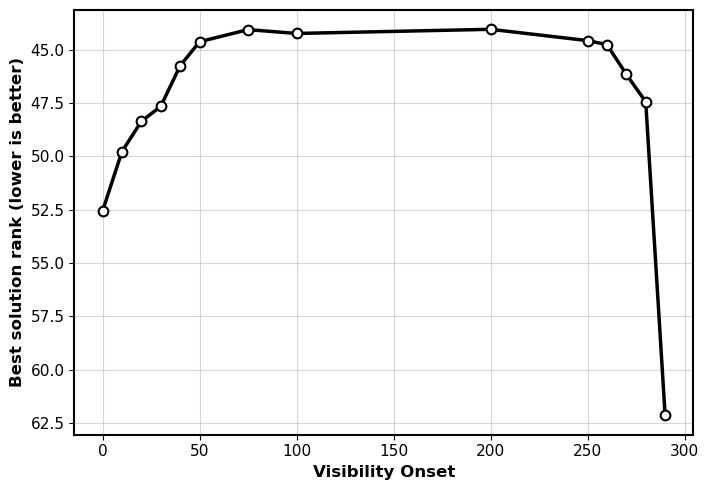

In [5]:
# Best solution rank across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
x = np.asarray(visibility_start_list)
y_rank = safe_nanmean(data['breakthrough_rank'], axis=1)
ax.plot(x, y_rank, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.invert_yaxis()  # Rank 1 is best; invert so a better rank is visually higher.
ax.set_xlabel('Visibility Onset', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Breakthrough_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

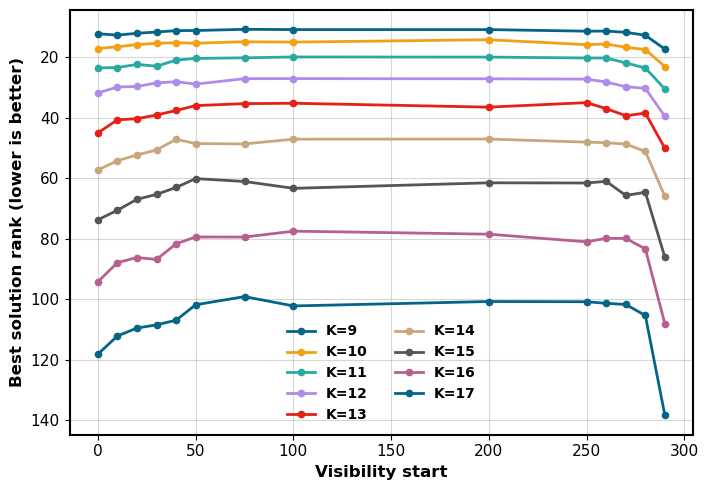

In [6]:
# Best solution rank across visibility start (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(visibility_start_list, data['breakthrough_rank'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.invert_yaxis()
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Breakthrough_by_K_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

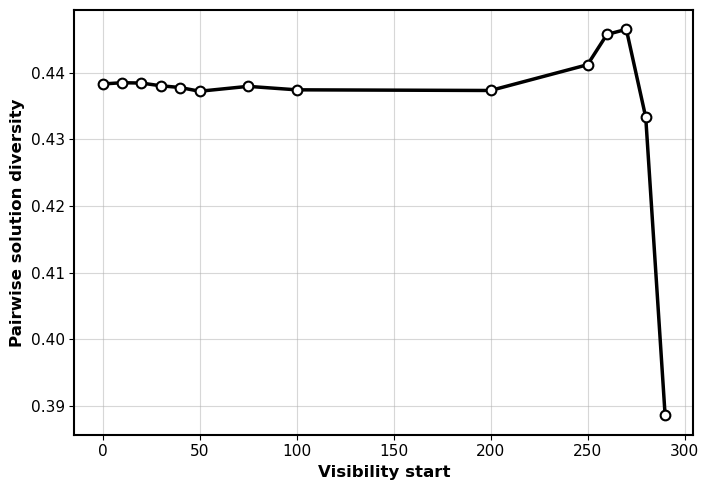

In [7]:
# Pairwise diversity across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_diversity = safe_nanmean(data['pairwise_diversity'], axis=1)
ax.plot(x, y_diversity, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Pairwise_diversity_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

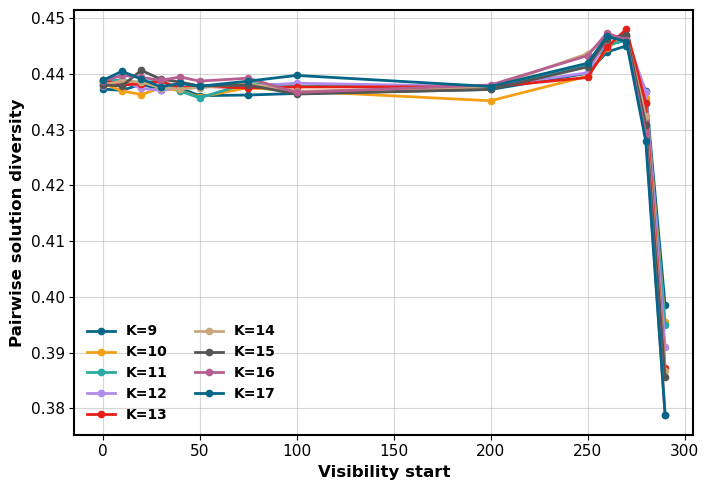

In [8]:
# Pairwise diversity across visibility start (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(visibility_start_list, data['pairwise_diversity'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Pairwise_diversity_by_K_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

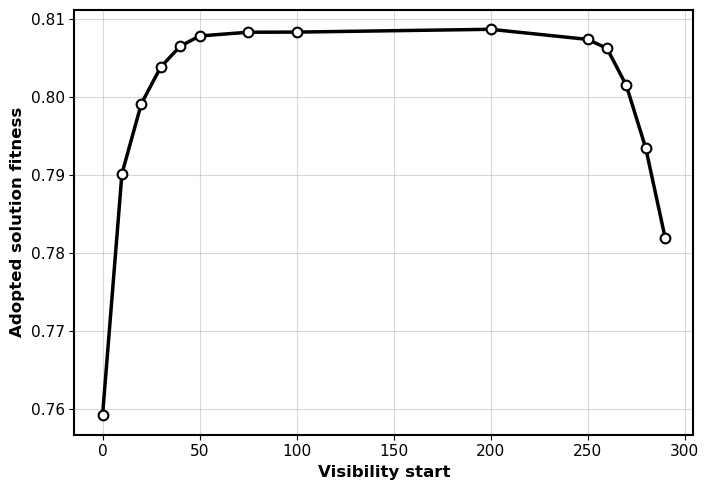

In [9]:
# Adopted solution fitness across visibility start (average across K).
# Undefined outcomes (when no adoption occurs) stay NaN and are not shown as zero.
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_adopted = safe_nanmean(data['adopted_solution_fitness'], axis=1)
ax.plot(x, y_adopted, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_quality_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

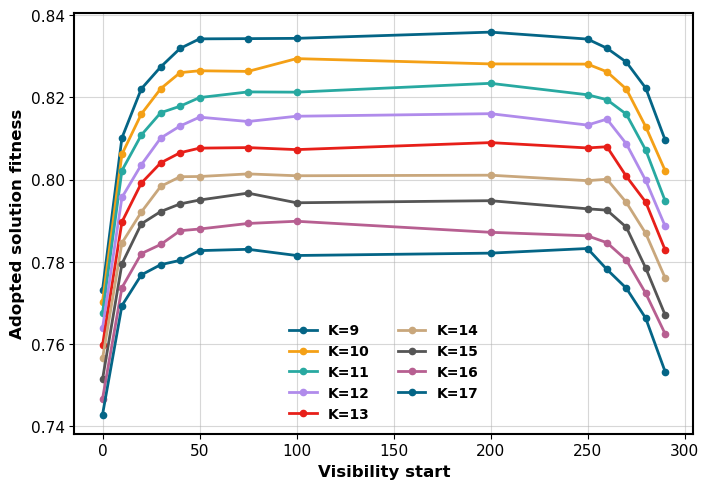

In [10]:
# Adopted solution fitness across visibility start (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(visibility_start_list, data['adopted_solution_fitness'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_fitness_by_K_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 4. Generative potential

The updated simulation records generative potential from uniformly sampled successful adoptions using independent post-adoption search continuations. Each saved `(start, K)` estimate is averaged across runs with qualifying adoption events. The figures follow the existing evaluator's line widths, markers, fonts, and grid styling. `NaN` entries remain undefined rather than being plotted as zero.

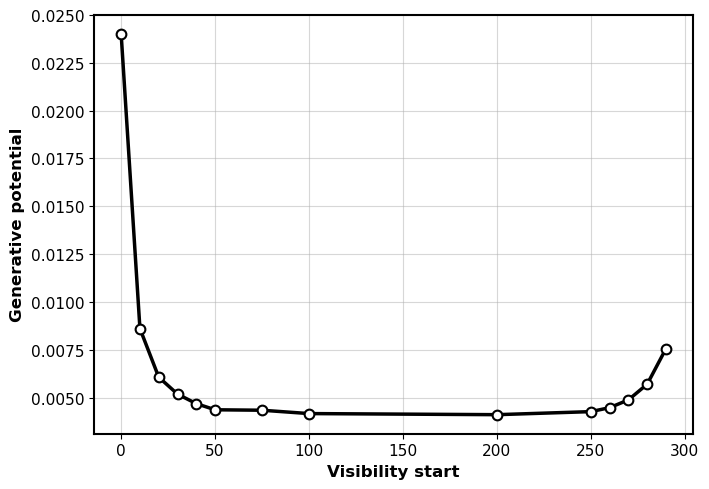

In [11]:
# Generative potential across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_generative = safe_nanmean(data['generative_potential'], axis=1)
ax.plot(x, y_generative, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Generative potential', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Generative_potential_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

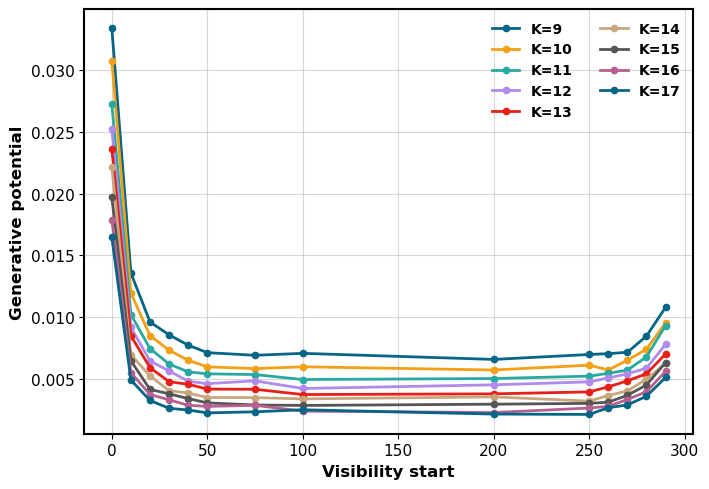

In [12]:
# Generative potential across visibility start (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(visibility_start_list, data['generative_potential'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Generative potential', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Generative_potential_by_K_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 5. Additional outcomes

`breakthrough_fitness` is the highest final receiver-solution fitness within a repetition; `breakthrough_rank` is the best final receiver solution's rank in the landscape. These are related but distinct summary scales. `unique_solution_count` captures the number of distinct final receiver solutions, whereas **pairwise diversity** captures how different those solutions are, even when uniqueness coincides.

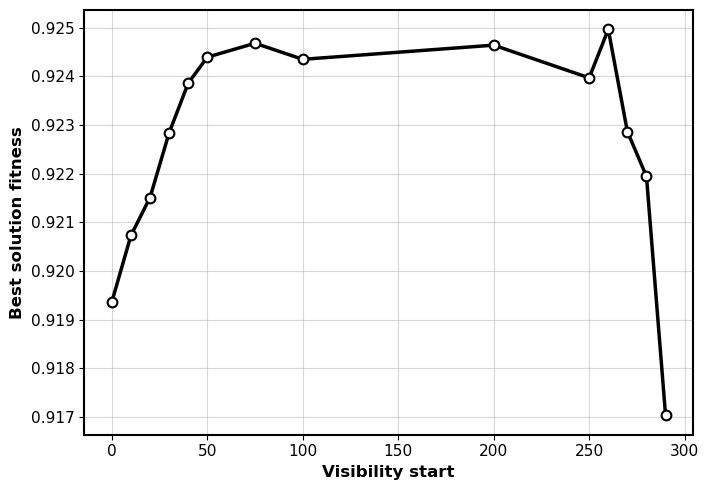

In [13]:
# Best solution fitness across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_fitness = safe_nanmean(data['breakthrough_fitness'], axis=1)
ax.plot(x, y_fitness, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Best_solution_fitness_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

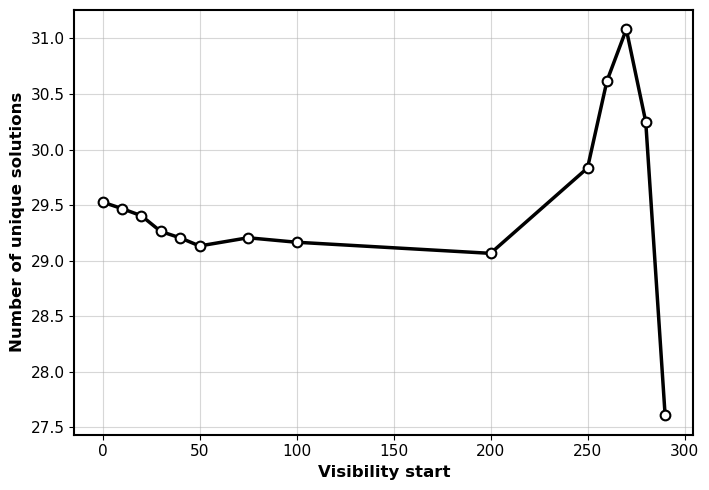

In [14]:
# Unique solution count across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_unique = safe_nanmean(data['unique_solution_count'], axis=1)
ax.plot(x, y_unique, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of unique solutions', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Unique_solution_count_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 6. Adoption-quality trajectories across search time

Set `trajectory_visibility_start` to any sampled visibility start. The horizontal axis gives actual **one-based search periods** when visibility occurs (for example, `1, 11, ..., 291` at start 0 and interval 10). Values are **cumulative mean fitness of adopted solutions through that event**, not fitness of only that period's adoptions or mean fitness of all receiver solutions. The first figure averages all K values; the second plots every K separately.

In [15]:
trajectory_visibility_start = 0  # Change to any entry in visibility_start_list.
if trajectory_visibility_start not in visibility_start_list:
    raise ValueError('trajectory_visibility_start must appear in visibility_start_list.')
trajectory_index = visibility_start_list.index(trajectory_visibility_start)
n_events = events_by_start[trajectory_visibility_start]
trajectory_periods = trajectory_visibility_start + 1 + np.arange(n_events) * visibility_interval
trajectory_by_K = data[trajectory_dv][trajectory_index, :, :n_events]  # (K, visibility event)
print('Trajectory start:', trajectory_visibility_start)
print('Visibility events:', len(trajectory_periods), '| last search period:', trajectory_periods[-1])
print('Defined trajectory entries:', np.isfinite(trajectory_by_K).sum(), '/', trajectory_by_K.size)

Trajectory start: 0
Visibility events: 30 | last search period: 291
Defined trajectory entries: 270 / 270


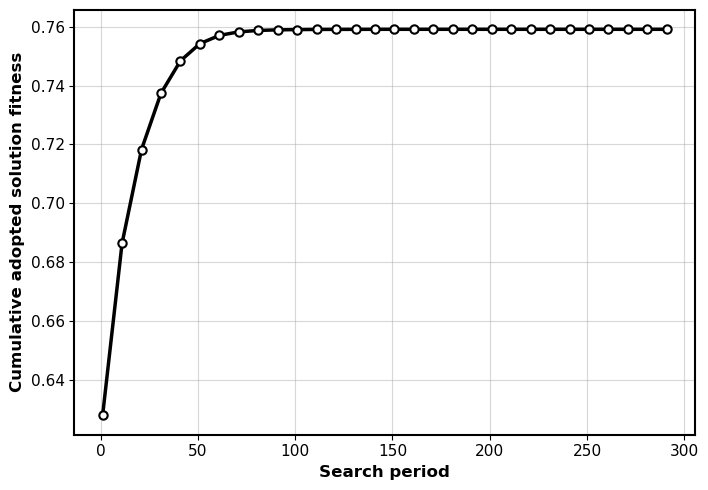

In [16]:
# Cumulative adopted solution fitness across search periods (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
trajectory_mean = safe_nanmean(trajectory_by_K, axis=0)
ax.plot(trajectory_periods, trajectory_mean, marker='o', linewidth=2.5,
        markersize=6, color='k', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_across_search_periods_start_{trajectory_visibility_start:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

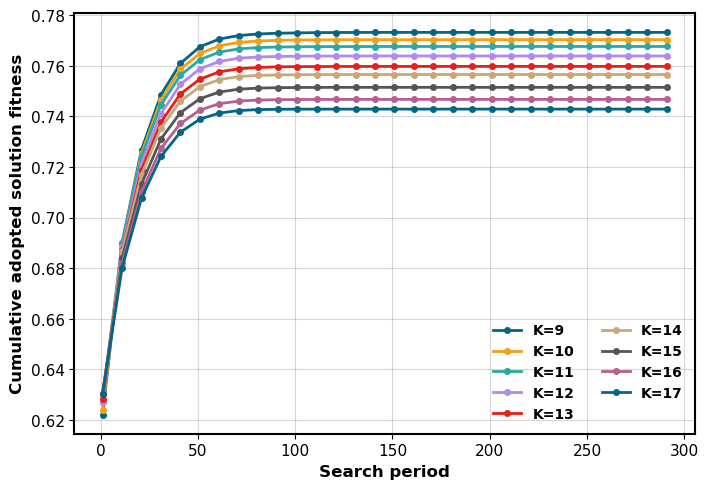

In [17]:
# Cumulative adopted solution fitness across search periods (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(trajectory_periods, trajectory_by_K[j], marker='o',
            linewidth=2.0, markersize=4, color=K_colors[j % len(K_colors)],
            label=f'K={K}')
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_start_{trajectory_visibility_start:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 7. Visibility timing × landscape complexity

These heatmaps display the underlying saved `(start, K)` averages without pooling across `K`. `NaN` cells remain blank, especially for adoption quality when no adoption occurs. The heatmaps also include generative potential. They help diagnose whether an overall trend is stable or masks heterogeneous responses across landscape complexity.

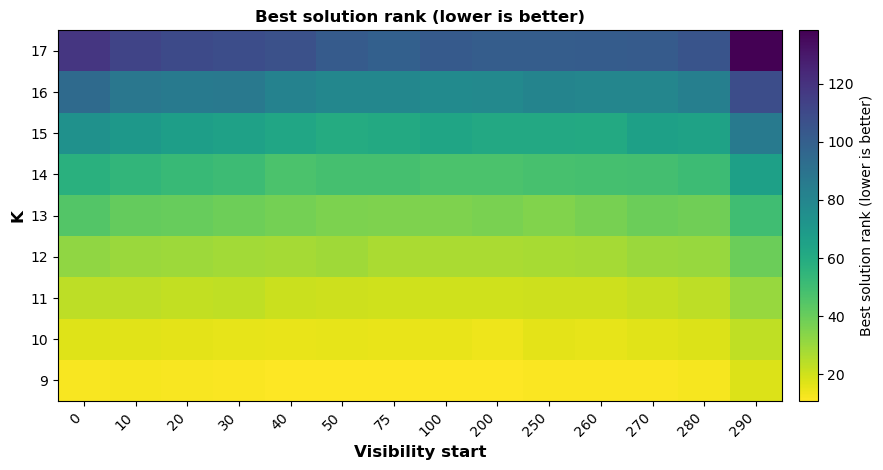

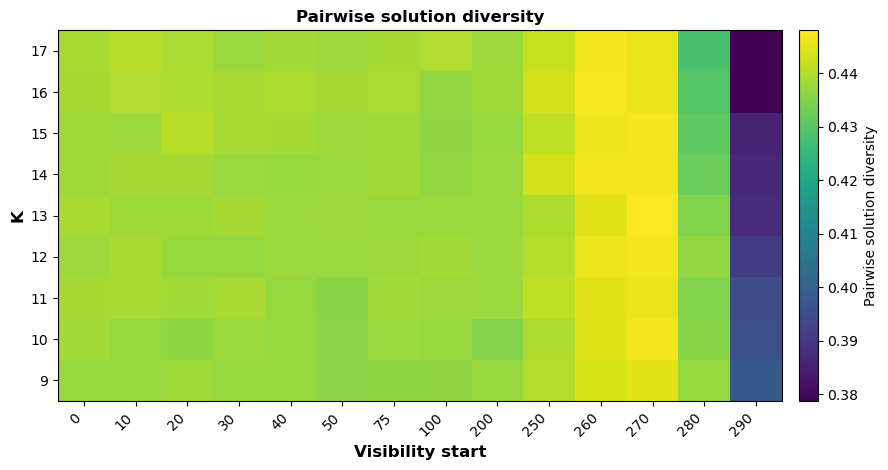

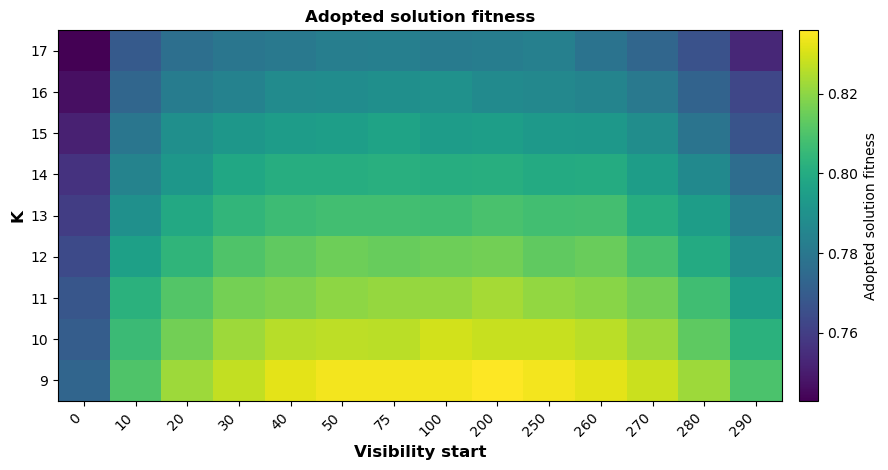

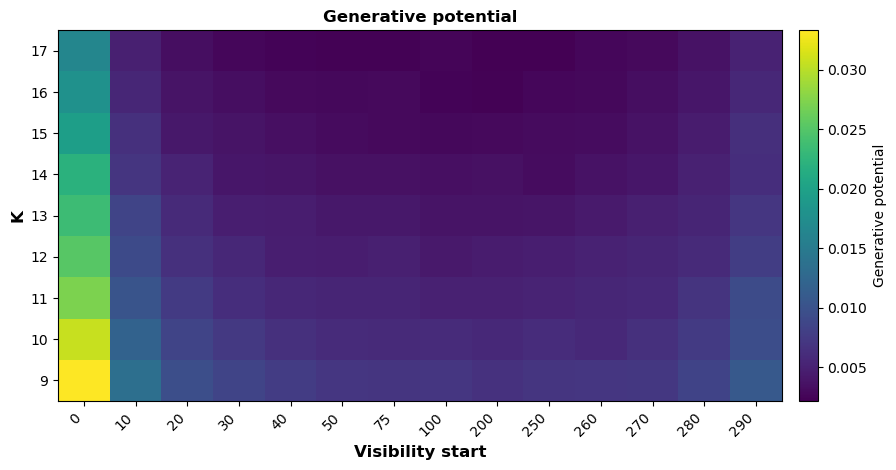

In [18]:
for dv, title, filename, cmap in [
    ('breakthrough_rank', 'Best solution rank (lower is better)', 'Best_solution_rank_heatmap_across_visibility_start_and_K.png', 'viridis_r'),
    ('pairwise_diversity', 'Pairwise solution diversity', 'Pairwise_diversity_heatmap_across_visibility_start_and_K.png', 'viridis'),
    ('adopted_solution_fitness', 'Adopted solution fitness', 'Adopted_solution_fitness_heatmap_across_visibility_start_and_K.png', 'viridis'),
    ('generative_potential', 'Generative potential', 'Generative_potential_heatmap_across_visibility_start_and_K.png', 'viridis'),
]:
    values = np.ma.masked_invalid(data[dv].T)  # (K, start)
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap=cmap, origin='lower')
    ax.set_xticks(np.arange(len(visibility_start_list)))
    ax.set_xticklabels([f'{start:g}' for start in visibility_start_list], rotation=45, ha='right')
    ax.set_yticks(np.arange(len(K_list)))
    ax.set_yticklabels(K_list)
    ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
    ax.set_ylabel('K', fontweight='bold', fontsize=12)
    ax.set_title(title, fontweight='bold', fontsize=12)
    fig.colorbar(image, ax=ax, label=title, pad=0.02)
    fig.tight_layout()
    # if save_figures:
    #     fig.savefig(figure_folder / filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()